### Laboratorio - Actividad 1 - Visión Artificial
## Mejora imagen - Operaciones elementales

**Objetivo:** comparar tres operaciones elementales, para mejorar la visibilidad de cuatro escenas urbanas nocturnas muy oscuras.

| Categoría | Técnica elegida | Idea |
|---|---|---|
| Transformación T | **Corrección gamma** | $s = 255\cdot (r/255)^{\gamma}$ con $\gamma<1$ aclara las sombras |
| Procesamiento del histograma | **CLAHE** | Ecualiza el histograma por regiones (*tiles*) limitando el contraste con `clip_limit` |
| Operación aritmética | **Multiplicación** | $s = k\cdot r$ escala linealmente el brillo |



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import math

## 1. Carga de las imágenes
OpenCV lee en BGR; se convierte a RGB para mostrar con Matplotlib.

In [3]:
rutas = {"4": "4.png", "104": "104.png", "204": "204.png", "304": "304.png"}

originales = {}
for nombre, ruta in rutas.items():
    bgr = cv2.imread(ruta)
    if bgr is None:
        raise FileNotFoundError(f"No se encontró {ruta}. Colócala en la misma carpeta que el cuaderno.")
    originales[nombre] = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

for nombre, img in originales.items():
    print(f"Imagen {nombre}: {img.shape}, dtype={img.dtype}")

Imagen 4: (720, 1080, 3), dtype=uint8
Imagen 104: (720, 1080, 3), dtype=uint8
Imagen 204: (720, 1080, 3), dtype=uint8
Imagen 304: (720, 1080, 3), dtype=uint8


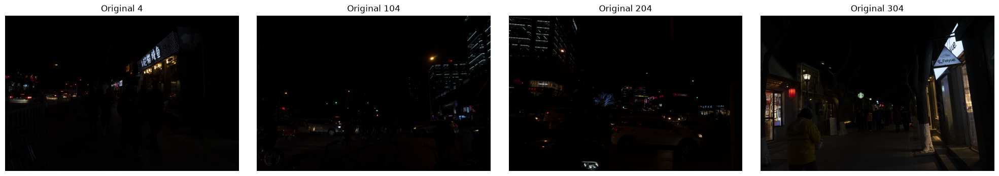

In [4]:
def plot_imagenes(imagenes, titulos=None, max_cols=4, figsize_base=(4, 4), cmap=None):
    n = len(imagenes)
    if n == 0:
        raise ValueError("La lista de imágenes está vacía")
    cols = min(n, max_cols)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(figsize_base[0]*cols, figsize_base[1]*rows))
    axes = np.atleast_1d(axes).flatten()
    for i, img in enumerate(imagenes):
        axes[i].imshow(img, cmap=(cmap or 'gray') if img.ndim == 2 else None)
        if titulos and i < len(titulos):
            axes[i].set_title(titulos[i])
        axes[i].axis('off')
    for j in range(n, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()

plot_imagenes(list(originales.values()), [f"Original {n}" for n in originales], max_cols=4, figsize_base=(5, 3.4))

## 2. Diagnóstico: histograma de las imágenes originales
Se muestra el histograma del canal **V** (brillo en HSV) con escala logarítmica en Y, junto con su **cumsum** (curva acumulada normalizada, línea azul sobre el eje derecho).

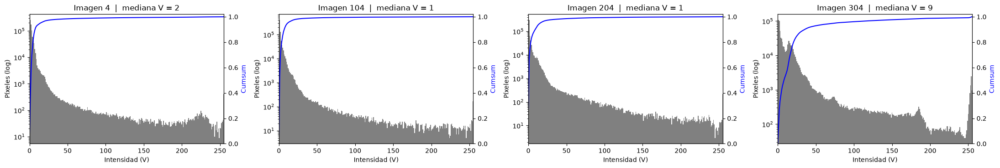

In [6]:
def canal_v(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)[:, :, 2]

def plot_hist_cumsum(ax, img_rgb, titulo, color="gray"):
    v = canal_v(img_rgb)
    hist = np.bincount(v.ravel(), minlength=256)
    ax.bar(range(256), hist, width=1.0, color=color)
    ax.set_yscale("log")
    ax.set_xlim(0, 255)
    ax.set_title(titulo)
    ax.set_xlabel("Intensidad (V)")
    ax.set_ylabel("Píxeles (log)")
    ax2 = ax.twinx()
    ax2.plot(hist.cumsum() / hist.sum(), color="blue")
    ax2.set_ylim(0, 1.02)
    ax2.set_ylabel("Cumsum", color="blue")

fig, axes = plt.subplots(1, 4, figsize=(22, 3.8))
for ax, (nombre, img) in zip(axes, originales.items()):
    plot_hist_cumsum(ax, img, f"Imagen {nombre}  |  mediana V = {np.median(canal_v(img)):.0f}")
plt.tight_layout()
plt.show()

**Observación:** la curva acumulada llega prácticamente al 100 % en los primeros niveles: casi todos los píxeles están "pegados" al negro y solo las fuentes de luz (farolas, letreros) llegan a valores altos. Una buena técnica debe **expandir las sombras sin quemar las luces**.

### Métricas
- **Brillo medio** y **contraste** (desviación estándar) del canal V.
- **Entropía** de V (en bits): mide cuánta variedad de tonos hay; más alta = más información tonal repartida.
- **% oscuros** (V < 30): información todavía "enterrada" en la sombra.
- **% saturados** (V ≥ 250): luces quemadas (información perdida).

In [7]:
def metricas(img_rgb):
    v = canal_v(img_rgb)
    p = np.bincount(v.ravel(), minlength=256) / v.size
    p = p[p > 0]
    return {
        "Brillo medio": v.mean(),
        "Contraste (std)": v.std(),
        "Entropía (bits)": -(p * np.log2(p)).sum(),
        "% oscuros (V<30)": 100 * (v < 30).mean(),
        "% saturados (V>=250)": 100 * (v >= 250).mean(),
    }

pd.DataFrame({n: metricas(i) for n, i in originales.items()}).T.round(2)

,Brillo medio,Contraste (std),Entropía (bits),% oscuros (V<30),% saturados (V>=250)
4,5.66,18.52,3.21,97.62,0.07
104,4.04,12.62,2.73,98.55,0.03
204,4.38,15.11,3.03,97.62,0.04
304,18.94,36.14,5.20,87.62,0.79


## 3. Técnica 1 (Transformación T): Corrección gamma

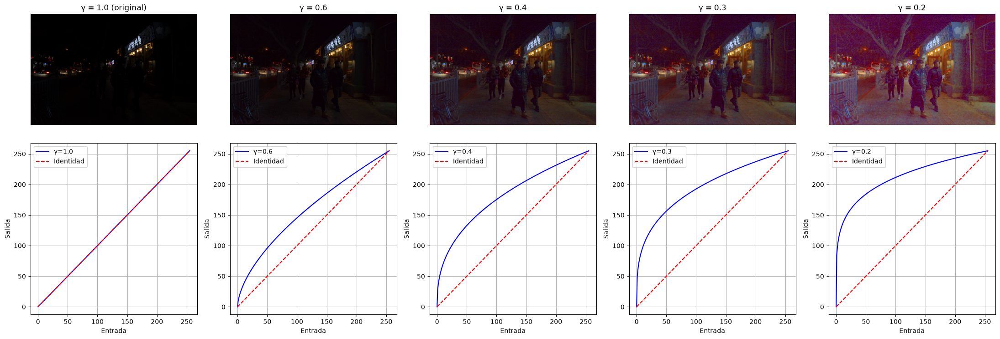

In [10]:
def correccion_gamma(img_rgb, gamma=0.4, c=255):
    lut = np.array([((i / 255.0) ** gamma) * c for i in range(256)]).clip(0, 255).astype("uint8")
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    hsv[:, :, 2] = cv2.LUT(hsv[:, :, 2], lut)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

gammas = [1.0, 0.6, 0.4, 0.3, 0.2]
base = originales["4"]
plt.figure(figsize=(22, 8))
for i, g in enumerate(gammas):
    plt.subplot(2, len(gammas), i + 1)
    plt.imshow(correccion_gamma(base, g))
    plt.title(f"γ = {g}" + (" (original)" if g == 1 else ""))
    plt.axis("off")
    plt.subplot(2, len(gammas), i + 1 + len(gammas))
    plt.plot(range(256), [255 * (x / 255) ** g for x in range(256)], color="blue", label=f"γ={g}")
    plt.plot(range(256), range(256), "r--", label="Identidad")
    plt.xlabel("Entrada"); plt.ylabel("Salida"); plt.grid(True); plt.legend()
plt.tight_layout()
plt.show()

Con $\gamma=0.6$ el efecto es tímido; con $\gamma=0.2$ la imagen se ve lavada. Un valor intermedio, **γ = 0.4**, será el usado en la comparación.

## 4. Técnica 2 (Histograma): CLAHE

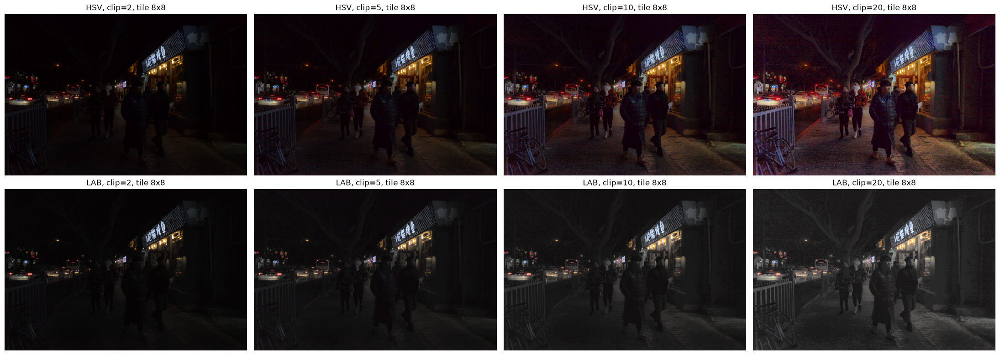

In [11]:
def aplicar_clahe(img_rgb, clip_limit=16, tile_grid_size=(8, 8), modelo="hsv"):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    if modelo == "hsv":
        hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
    elif modelo == "lab":
        lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
        lab[:, :, 0] = clahe.apply(lab[:, :, 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    raise ValueError("modelo debe ser 'hsv' o 'lab'")

# Fila 1: variar clip_limit (tile 8x8, HSV). Fila 2: LAB con los mismos clip_limit
clips = [2, 5, 10, 20]
base = originales["4"]
plt.figure(figsize=(22, 8))
for i, cl in enumerate(clips):
    plt.subplot(2, 4, i + 1)
    plt.imshow(aplicar_clahe(base, cl, (8, 8), "hsv")); plt.title(f"HSV, clip={cl}, tile 8x8"); plt.axis("off")
    plt.subplot(2, 4, i + 5)
    plt.imshow(aplicar_clahe(base, cl, (8, 8), "lab")); plt.title(f"LAB, clip={cl}, tile 8x8"); plt.axis("off")
plt.tight_layout()
plt.show()

**Lectura:** con `clip_limit` bajo (2 a 5) apenas cambia la imagen, porque el recorte impide estirar histogramas tan estrechos. LAB aclara menos que HSV con el mismo `clip_limit` y se ve más grisáceo. Con valores altos, HSV revela mucho detalle pero con un tinte rojizo/magenta en las sombras (el ruido de color se amplifica). Se usará **HSV con clip_limit = 16 y tiles 8×8**.

Ahora el efecto del tamaño de rejilla (cantidad de tiles por lado, no su tamaño en píxeles):

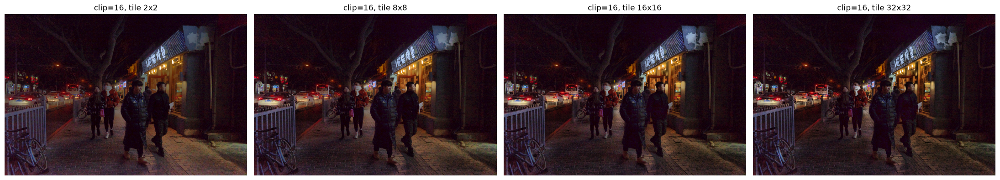

In [12]:
tiles = [(2, 2), (8, 8), (16, 16), (32, 32)]
plt.figure(figsize=(22, 4.2))
for i, t in enumerate(tiles):
    plt.subplot(1, 4, i + 1)
    plt.imshow(aplicar_clahe(base, 16, t, "hsv")); plt.title(f"clip=16, tile {t[0]}x{t[1]}"); plt.axis("off")
plt.tight_layout()
plt.show()

Pocos tiles (2×2) se parece a una ecualización casi global; muchos tiles (32×32) dan un realce muy local y más ruido. 8×8 es un buen compromiso.

## 5. Técnica 3 (Aritmética): Multiplicación por una constante

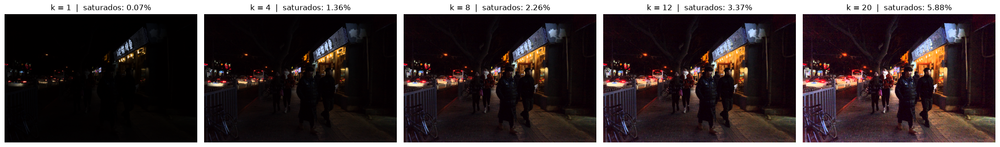

In [13]:
def multiplicacion(img_rgb, k=8):
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    v = hsv[:, :, 2].astype(np.float32) * k
    hsv[:, :, 2] = np.clip(v, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

ks = [1, 4, 8, 12, 20]
plt.figure(figsize=(22, 4.2))
for i, k in enumerate(ks):
    plt.subplot(1, len(ks), i + 1)
    r = multiplicacion(originales["4"], k)
    plt.imshow(r)
    plt.title(f"k = {k}  |  saturados: {100*(canal_v(r) >= 250).mean():.2f}%")
    plt.axis("off")
plt.tight_layout()
plt.show()

Al subir $k$ crecen los halos alrededor de letreros y farolas y las sombras siguen oscuras. Se usará **k = 8**.

## 6. Comparación de las tres técnicas
Parámetros: **γ = 0.4**, **CLAHE (HSV, clip 16, tiles 8×8)** y **k = 8**.

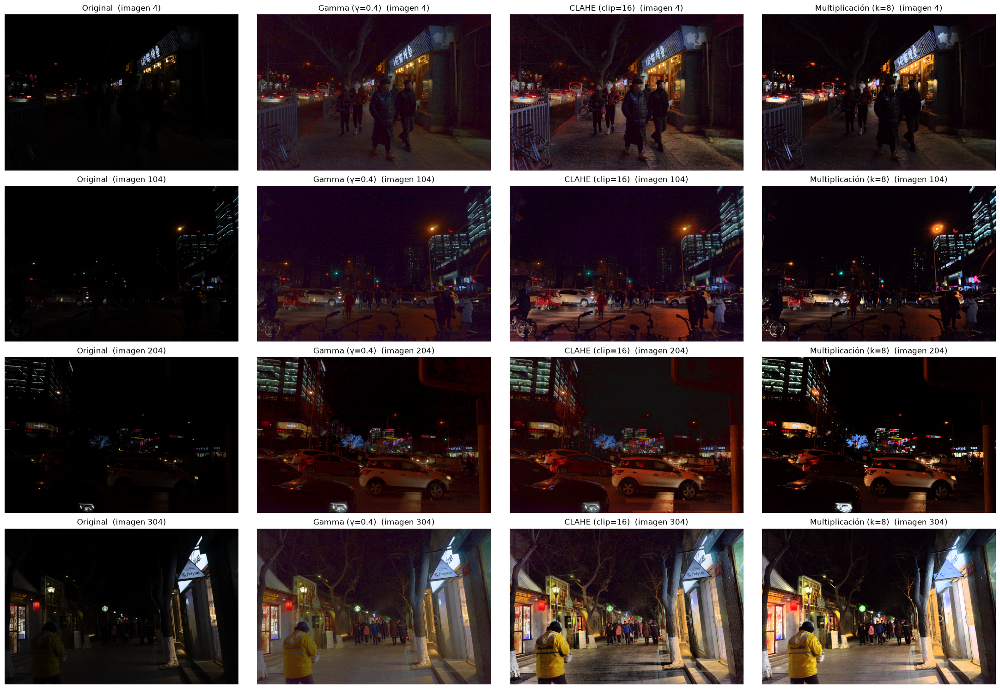

In [14]:
GAMMA, CLIP, TILE, K = 0.4, 16, (8, 8), 8

tecnicas = {
    "Original": lambda im: im,
    f"Gamma (γ={GAMMA})": lambda im: correccion_gamma(im, GAMMA),
    f"CLAHE (clip={CLIP})": lambda im: aplicar_clahe(im, CLIP, TILE, "hsv"),
    f"Multiplicación (k={K})": lambda im: multiplicacion(im, K),
}

resultados = {n: {t: f(img) for t, f in tecnicas.items()} for n, img in originales.items()}

fig, axes = plt.subplots(4, 4, figsize=(22, 15))
for r, nombre in enumerate(originales):
    for c, (t, img) in enumerate(resultados[nombre].items()):
        axes[r, c].imshow(img)
        axes[r, c].axis("off")
        axes[r, c].set_title(f"{t}  (imagen {nombre})")
plt.tight_layout()
plt.show()

### Histogramas tras cada técnica (imagen 4)
Aquí se ve la diferencia de fondo entre las tres: gamma **curva** el histograma, la multiplicación lo **estira** (y lo corta en 255) y CLAHE lo **redistribuye localmente**.

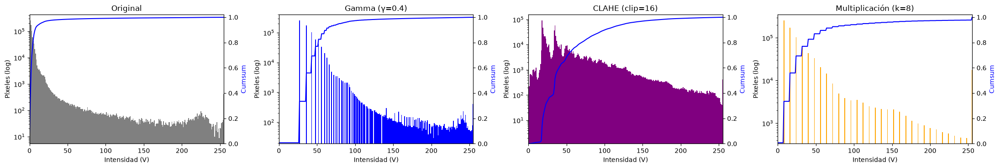

In [15]:
colores = ["gray", "blue", "purple", "orange"]
fig, axes = plt.subplots(1, 4, figsize=(22, 3.8))
for ax, (t, img), col in zip(axes, resultados["4"].items(), colores):
    plot_hist_cumsum(ax, img, f"{t}", color=col)
plt.tight_layout()
plt.show()

### Comparación cuantitativa

In [16]:
filas = []
for nombre, res in resultados.items():
    for t, img in res.items():
        filas.append({"Imagen": nombre, "Técnica": t, **metricas(img)})

tabla = pd.DataFrame(filas).round(2)
tabla

,Imagen,Técnica,Brillo medio,Contraste (std),Entropía (bits),% oscuros (V<30),% saturados (V>=250)
0,4,Original,5.66,18.52,3.21,97.62,0.07
1,4,Gamma (γ=0.4),43.33,25.28,3.20,33.51,0.09
2,4,CLAHE (clip=16),48.77,38.70,6.17,37.25,0.09
3,4,Multiplicación (k=8),32.22,45.36,3.04,69.39,2.26
4,104,Original,4.04,12.62,2.73,98.55,0.03
5,104,Gamma (γ=0.4),38.54,21.56,2.72,53.24,0.04
6,104,CLAHE (clip=16),43.91,35.38,5.96,53.41,0.04
7,104,Multiplicación (k=8),26.24,40.25,2.63,76.93,1.35
8,204,Original,4.38,15.11,3.03,97.62,0.04
9,204,Gamma (γ=0.4),31.19,30.51,3.03,65.97,0.04


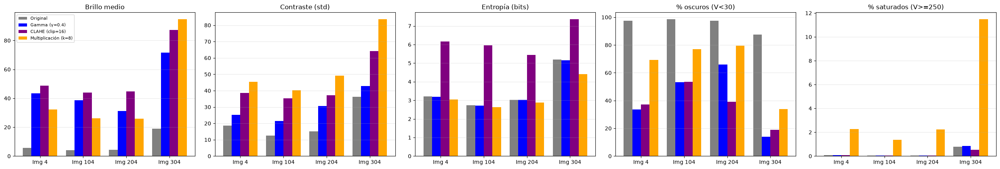

In [17]:
metricas_graf = ["Brillo medio", "Contraste (std)", "Entropía (bits)", "% oscuros (V<30)", "% saturados (V>=250)"]
nombres_tec = list(tecnicas.keys())
etiquetas = list(originales.keys())
ancho = 0.2

fig, axes = plt.subplots(1, 5, figsize=(26, 4.5))
for ax, met in zip(axes, metricas_graf):
    for j, (t, col) in enumerate(zip(nombres_tec, colores)):
        vals = [tabla[(tabla["Imagen"] == n) & (tabla["Técnica"] == t)][met].values[0] for n in etiquetas]
        ax.bar(np.arange(len(etiquetas)) + j * ancho, vals, ancho, label=t, color=col)
    ax.set_xticks(np.arange(len(etiquetas)) + 1.5 * ancho)
    ax.set_xticklabels([f"Img {n}" for n in etiquetas])
    ax.set_title(met)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Zoom a una zona oscura (imagen 4)

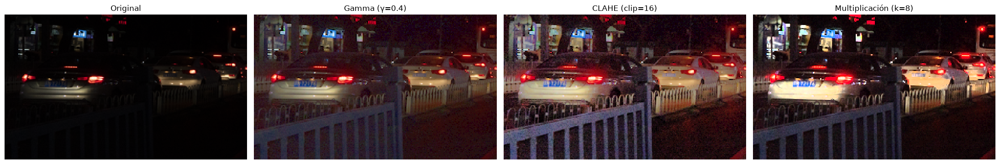

In [18]:
y0, y1, x0, x1 = 300, 480, 0, 300   # zona de coches
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (t, img) in zip(axes, resultados["4"].items()):
    ax.imshow(img[y0:y1, x0:x1], interpolation="nearest")
    ax.set_title(t)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Zoom a una zona de luz (imagen 304)

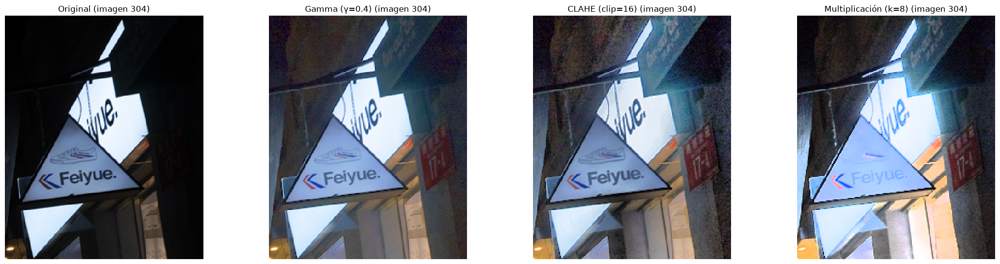

In [19]:
y0, y1, x0, x1 = 30, 300, 780, 1000   # letrero luminoso "Feiyue"
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (t, img) in zip(axes, resultados["304"].items()):
    ax.imshow(img[y0:y1, x0:x1], interpolation="nearest")
    ax.set_title(f"{t} (imagen 304)")
    ax.axis("off")
plt.tight_layout()
plt.show()